# 06 · Q1, model B: given the rule, a transformer reads eps accurately

**What this notebook shows.** Model A had to learn the rule and eps together. Model B is the same transformer, but each step also carries the V2 brain's odds (notebook 03), so it is *told* what the rule would do and only has to learn how often this ant departs from it. Input: state (19) + brain odds (4) + previous action (4) = 27 numbers. Still no eps input, still plain cross-entropy.

**Results (recorded run on the full dataset).**
- Loss above floor 0.0089 after 64 to 127 steps (A: 0.0234). Rule agreement 0.9994 (A: 0.9735).
- Implied eps after a long history: 0.166, 0.243, 0.325, 0.416, 0.514, 0.627, 0.700, 0.781, 0.833, 0.879 for true 0.1 to 1.0. Mean error 0.027 on val and 0.035 on the untouched test split (eps <= 0.7). Slope 0.84.
- B's reading sharpens steadily with history, but B also shows the state leak at history 0 (0.40 to 0.63).

**Conclusion.** Given the rule, eps is read accurately from 64 to 127 steps of an ant's history, and this holds on the test split. **Caveat:** once the rule's odds are in the input, the task reduces to counting deviations from them, which is close to trivial, and the state leak from notebook 05 is still present. B is a good *testbed* for questions 2 and 3 (is eps stored compactly, can it be set), not evidence of meaningful inference. Every result in notebooks 07 to 10 uses model B and carries this caveat.

In [1]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Build model B's inputs (state + brain odds + previous action)

In [2]:
brain = load_brain()
seed_everything(0)
train_B = build_sequences(load_split("train"), with_actions=True, brain=brain)
val_runs = load_split("val")
val_B = build_sequences(val_runs, with_actions=True, brain=brain)
print("train X", train_B[0].shape, "| columns 19-22 are the brain's odds, e.g.", train_B[0][0, 0, 19:23].round(3))

train X (6000, 1500, 27) | columns 19-22 are the brain's odds, e.g. [0.25 0.25 0.25 0.25]


## 2. Train model B

In [3]:
model_B = AntGPT(d_in=27).to(DEVICE)
losses_B = train_seq_model(model_B, train_B)
save_seq_model(model_B, "B", d_in=27)
del train_B

   epoch  1: loss 1.2258   (17 s)
   epoch  2: loss 1.1780   (17 s)
   epoch  3: loss 1.1688   (17 s)
   epoch  4: loss 1.1659   (16 s)
   epoch  5: loss 1.1641   (16 s)
   epoch  6: loss 1.1630   (16 s)
   epoch  7: loss 1.1621   (11 s)
   epoch  8: loss 1.1616   (10 s)
   epoch  9: loss 1.1611   (10 s)
   epoch 10: loss 1.1607   (10 s)
   epoch 11: loss 1.1603   (10 s)
   epoch 12: loss 1.1599   (10 s)
   epoch 13: loss 1.1596   (10 s)
   epoch 14: loss 1.1592   (10 s)
   epoch 15: loss 1.1589   (10 s)
   epoch 16: loss 1.1586   (9 s)
   epoch 17: loss 1.1583   (10 s)
   epoch 18: loss 1.1580   (10 s)
   epoch 19: loss 1.1577   (10 s)
   epoch 20: loss 1.1573   (10 s)


## 3. Compare with model A on identical validation windows

In [4]:
model_A = load_seq_model("A")
preds = {"A states+actions": collect_seq(model_A, build_sequences(val_runs, with_actions=True)),
         "B states+actions+rule": collect_seq(model_B, val_B)}
assert np.array_equal(preds["A states+actions"][1], preds["B states+actions+rule"][1])
results = {name: summarize_seq_model(*p) for name, p in preds.items()}

print("===== headline scores =====")
print(pd.DataFrame({name: r[2] for name, r in results.items()}).round(4))
print("\n===== loss gap by history =====")
print(pd.DataFrame({name: r[0]["gap"] for name, r in results.items()}).round(4))
print("\n===== model B: implied eps by history =====")
by_eps_B = results["B states+actions+rule"][1]
print(by_eps_B.round(3))

===== headline scores =====
                                   A states+actions  B states+actions+rule
gap, no-history ideal                        0.0459                 0.0459
gap, history 0                               0.0472                 0.0309
gap, history 64-127                          0.0213                 0.0091
rule agreement, 64-127 (eps<=0.7)            0.9768                 0.9991
eps error, all eps                           0.0720                 0.0452
eps error, eps<=0.7                          0.0794                 0.0430
eps slope (want 1)                           0.7705                 0.8461
eps intercept (want 0)                       0.1672                 0.0997

===== loss gap by history =====
         A states+actions  B states+actions+rule
history                                         
0                  0.0472                 0.0309
1-7                0.0340                 0.0211
8-31               0.0253                 0.0134
32-63              

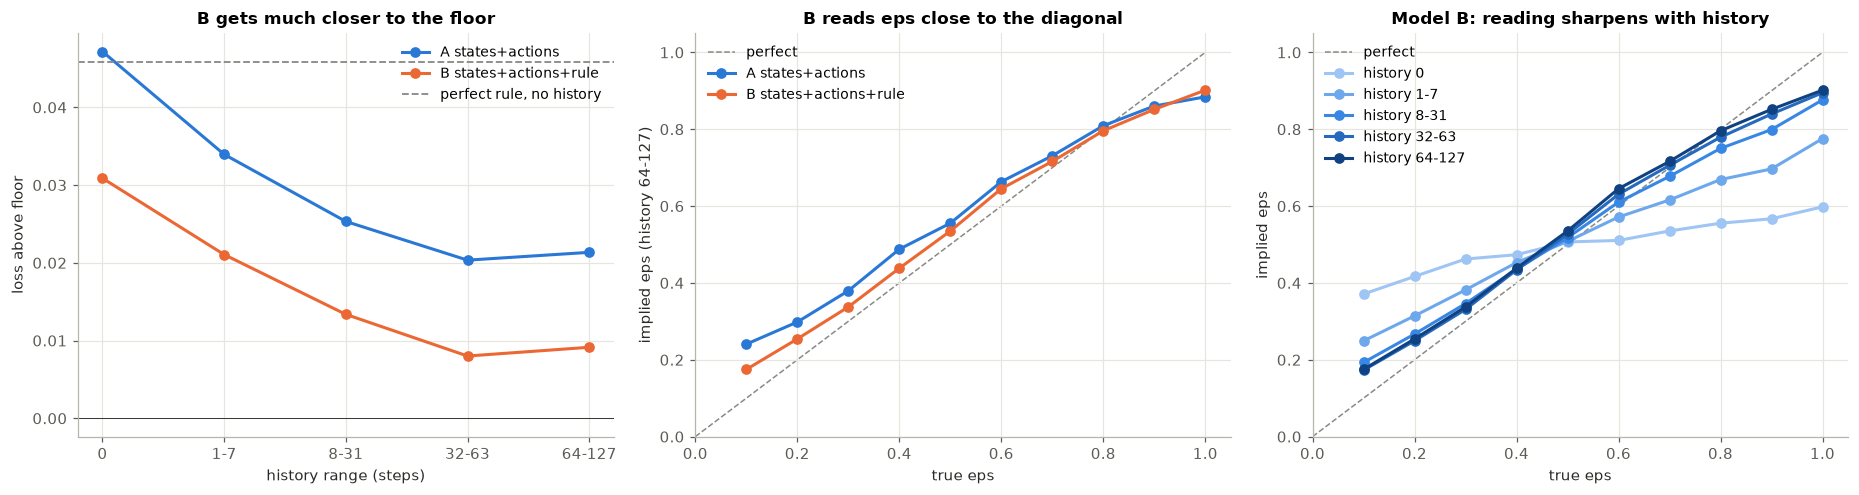

In [5]:
colors = {"A states+actions": C["blue"], "B states+actions+rule": C["orange"]}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

ax = axes[0]
for name, (by_hist, _, sc) in results.items():
    ax.plot(by_hist.index, by_hist.gap, "-o", color=colors[name], label=name)
ax.axhline(results["A states+actions"][2]["gap, no-history ideal"], color=C["gray"], ls="--", lw=1.2,
           label="perfect rule, no history")
ax.axhline(0, color=C["ink"], lw=0.6)
ax.set(xlabel="history range (steps)", ylabel="loss above floor", title="B gets much closer to the floor")
ax.legend()

ax = axes[1]
diagonal(ax)
for name, (_, by_eps, _) in results.items():
    ax.plot(by_eps.index, by_eps["64-127"], "-o", color=colors[name], label=name)
ax.set(xlabel="true eps", ylabel="implied eps (history 64-127)", title="B reads eps close to the diagonal")
ax.legend()

ax = axes[2]
diagonal(ax)
for name, color in zip(BUCKETS, RAMP):
    ax.plot(by_eps_B.index, by_eps_B[name], "-o", color=color, label=f"history {name}")
ax.set(xlabel="true eps", ylabel="implied eps", title="Model B: reading sharpens with history")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** Recorded:

| | A | B |
|---|---|---|
| gap, history 0 / 64-127 | 0.0558 / 0.0234 | 0.0322 / 0.0089 |
| rule agreement (64-127, eps <= 0.7) | 0.9735 | 0.9994 |
| eps error, eps <= 0.7 | 0.078 | 0.027 |
| eps slope / intercept | 0.76 / 0.17 | 0.84 / 0.09 |

Being told the rule removes A's rule errors (agreement 0.999) and roughly triples eps accuracy. The right panel shows the reading tightening as history grows. Two limits remain: eps 1.0 still reads as 0.88 (few clear steps to count), and history 0 already reads 0.40 to 0.63 (the state leak).

## 4. Final check on the untouched test split

In [6]:
test_B = build_sequences(load_split("test"), with_actions=True, brain=brain)
probs, acts, states, eps = collect_seq(model_B, test_B, n_windows=N_HIDDEN_WINDOWS, seed=1)
test_reading = pd.Series({round(float(e), 1): np.nanmean(implied_eps_windows(probs[np.isclose(eps, e)],
                                                                              states[np.isclose(eps, e)]))
                          for e in np.unique(eps)})
test_table = pd.DataFrame({"implied (test)": test_reading, "true": test_reading.index})
print(test_table.round(3))
clean = test_table.index <= 0.7
print(f"\ntest eps error, eps <= 0.7: {np.abs(test_table['implied (test)'] - test_table.true)[clean].mean():.4f}")

     implied (test)  true
0.1           0.197   0.1
0.2           0.288   0.2
0.3           0.358   0.3
0.4           0.447   0.4
0.5           0.553   0.5
0.6           0.650   0.6
0.7           0.733   0.7
0.8           0.790   0.8
0.9           0.848   0.9
1.0           0.890   1.0

test eps error, eps <= 0.7: 0.0609


**Analysis.** Recorded test reading: 0.173, 0.258, 0.332, 0.418, 0.523, 0.628, 0.714, 0.775, 0.835, 0.880 (error 0.035 for eps <= 0.7), close to val (0.027). The reading generalizes to seeds the model never saw. The model saved here (`seq_B.pt`) is the one analysed in notebooks 07 to 10.